# Sample Run with trVAE for Kang et. al dataset

In [ ]:
import sys
print(sys.executable)

import tensorflow as tf
print(tf.__version__)
print(tf.__file__)
print(hasattr(tf, "placeholder"))

import keras
print(keras.__version__)
print(keras.__file__)

/home/karimpour/miniconda3/envs/trvae_tensor/bin/python
1.15.2
/home/karimpour/miniconda3/envs/trvae_tensor/lib/python3.7/site-packages/tensorflow/__init__.py

True
2.2.4
/home/karimpour/miniconda3/envs/trvae_tensor/lib/python3.7/site-packages/keras/__init__.py


Using TensorFlow backend.


In [2]:
# import os
# os.chdir("../")
# import sys
sys.path.insert(0, "/home/karimpour/sc_perturb/sc_proj/models/trVAE")
import reptrvae

In [3]:
import numpy as np
import scanpy as sc
import pandas as pd 
from scipy import stats

In [4]:
sc.settings.set_figure_params(dpi=200)

In [5]:
data_name = "kang"
specific_celltype = "NK"
# conditions = ['control', 'stimulated']
conditions = ['ctrl', 'stimulated']
target_conditions = ["stimulated"]
cell_type_key = "cell_type"
condition_key = "condition"

In [6]:
# adata = sc.read(f"./data/{data_name}/{data_name}_normalized.h5ad")
path_to_data = f'/home/karimpour/sc_perturb/inputs/datasets/{data_name}/{data_name}_normalized_hvg.h5ad'
adata = sc.read(path_to_data)
adata = adata[adata.obs[condition_key].isin(conditions)].copy()
adata

AnnData object with n_obs × n_vars = 13576 × 5000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'stim', 'seurat_annotations', 'integrated_snn_res.0.5', 'seurat_clusters', 'condition', 'cell_type', 'cov_cond', 'split_CD14 Mono', 'split_CD4 T', 'split_T', 'split_CD8 T', 'split_B', 'split_DC', 'split_CD16 Mono', 'split_NK'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'symbol'
    uns: 'hvg', 'log1p', 'rank_genes_groups_cov'
    layers: 'counts'

In [7]:
adata.obs[cell_type_key].value_counts()

CD14 Mono    4362
CD4 T        4266
B            1366
CD16 Mono    1044
CD8 T         814
T             633
NK            619
DC            472
Name: cell_type, dtype: int64

In [8]:
adata.obs.groupby([cell_type_key, condition_key]).size()

cell_type  condition 
B          ctrl           592
           stimulated     774
CD4 T      ctrl          1837
           stimulated    2429
CD8 T      ctrl           352
           stimulated     462
CD14 Mono  ctrl          2215
           stimulated    2147
CD16 Mono  ctrl           507
           stimulated     537
DC         ctrl           258
           stimulated     214
NK         ctrl           298
           stimulated     321
T          ctrl           300
           stimulated     333
dtype: int64

In [9]:
adata.X.min(), adata.X.max()

(0.0, 3828.0)

In [10]:
count_per_cell = 1e4
# count_per_cell = None
sc.pp.normalize_total(adata, target_sum=count_per_cell)
sc.pp.log1p(adata)

In [11]:
gene_size = 2000
sc.pp.highly_variable_genes(adata, flavor='seurat', n_top_genes=gene_size, subset=False)
adata = adata[:, adata.var['highly_variable']].copy()
# hvg = adata.var_names[adata.var["highly_variable"]].to_numpy()
# adata = adata[:, hvg].copy()

In [12]:
adata.X.min(), adata.X.max()

(0.0, 9.0423)

In [13]:
train_adata, valid_adata = reptrvae.utils.train_test_split(adata, 0.80)

In [14]:
train_adata.shape, valid_adata.shape

((10860, 2000), (2716, 2000))

In [15]:
net_train_adata = train_adata[~((train_adata.obs[cell_type_key] == specific_celltype) & (train_adata.obs[condition_key].isin(target_conditions)))]
net_valid_adata = valid_adata[~((valid_adata.obs[cell_type_key] == specific_celltype) & (valid_adata.obs[condition_key].isin(target_conditions)))]

In [16]:
net_train_adata.shape, net_valid_adata.shape

((10611, 2000), (2644, 2000))

In [17]:
net_train_adata.obs.groupby([cell_type_key, condition_key]).size()

cell_type  condition 
B          ctrl           478
           stimulated     612
CD4 T      ctrl          1524
           stimulated    1959
CD8 T      ctrl           278
           stimulated     359
CD14 Mono  ctrl          1781
           stimulated    1693
CD16 Mono  ctrl           385
           stimulated     422
DC         ctrl           206
           stimulated     161
NK         ctrl           245
           stimulated       0
T          ctrl           241
           stimulated     267
dtype: int64

In [18]:
path_to_save = './'
network = reptrvae.models.trVAE(x_dimension=net_train_adata.shape[1],
                                conditions = conditions,
                                z_dimension=20,
                                mmd_dimension=128, 
                                n_conditions=len(net_train_adata.obs[condition_key].unique()),
                                alpha=1e-6,
                                beta=500,
                                eta=100,
                                clip_value=1e6,
                                lambda_l1=0.0,
                                lambda_l2=0.0,
                                learning_rate=0.001,
#                                 model_path=f"./models/trVAEMulti/best/{data_name}-{specific_celltype}/",
                                model_path=f"./normalize_count_{count_per_cell}/",
                                dropout_rate=0.2,
                                output_activation='relu')




Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.





Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
data (InputLayer)               (None, 2000)         0                                            
__________________________________________________________________________________________________
encoder_labels (InputLayer)     (None, 2)            0                                            
__________________________________________________________________________________________________
concatenate_1 (Concatenate)     (None, 2002)         0           data[0][0]                       
                                                                 encoder_labels[0][0]     

In [19]:
label_encoder = {'ctrl': 0, 'stimulated': 1}

In [ ]:
# network.restore_model()

2026-07-26 14:29:39.760535: I tensorflow/core/platform/cpu_feature_guard.cc:142] Your CPU supports instructions that this TensorFlow binary was not compiled to use: AVX2 FMA
2026-07-26 14:29:39.773476: I tensorflow/core/platform/profile_utils/cpu_utils.cc:94] CPU Frequency: 2200065000 Hz
2026-07-26 14:29:39.779855: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x5b33faecfcc0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2026-07-26 14:29:39.779874: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Host, Default Version


In [20]:
network.train(net_train_adata,
              net_valid_adata,
              label_encoder,
              condition_key,
              n_epochs=10000,
              batch_size=128,
              verbose=2,
              early_stop_limit=500,
              lr_reducer=400,
              shuffle=True,
              )




Train on 10611 samples, validate on 2644 samples
Epoch 1/10000






2026-07-26 15:16:05.391947: I tensorflow/core/platform/cpu_feature_guard.cc:142] Your CPU supports instructions that this TensorFlow binary was not compiled to use: AVX2 FMA
2026-07-26 15:16:05.404585: I tensorflow/core/platform/profile_utils/cpu_utils.cc:94] CPU Frequency: 2200065000 Hz
2026-07-26 15:16:05.411677: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x64002a7f94d0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2026-07-26 15:16:05.411694: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Host, Default Version



 - 7s - loss: 3964749.5880 - kl_mse_loss: 3964713.1260 - mmd_loss: 36.4452 - val_loss: 3563019.3147 - val_kl_mse_loss: 3562974.0813 - val_mmd_loss: 45.2370
Epoch 2/10000
 - 5s - loss: 3558137.3321 - kl_mse_loss: 3558098.5034 - mmd_loss: 38.8376 - val_loss: 3352331.9766 - val_kl_mse_loss: 3352290.5011 - val_mmd_loss: 41.4564
Epoch 3/10000
 - 5s - loss: 3482914.6669 - kl_mse_loss: 3482880.4687 - mmd_loss: 34.1995 - val_loss: 3275933.4985 - val_kl_mse_loss: 3275897.8264 - val_mmd_loss: 35.6874
Epoch 4/10000
 - 5s - loss: 3434081.4317 - kl_mse_loss: 3434049.8048 - mmd_loss: 31.6245 - val_loss: 3237683.2290 - val_kl_mse_loss: 3237648.7262 - val_mmd_loss: 34.4958
Epoch 5/10000
 - 5s - loss: 3400743.2696 - kl_mse_loss: 3400712.8462 - mmd_loss: 30.4205 - val_loss: 3209409.5596 - val_kl_mse_loss: 3209376.5204 - val_mmd_loss: 33.0272
Epoch 6/10000
 - 5s - loss: 3374460.5553 - kl_mse_loss: 3374430.9504 - mmd_loss: 29.6047 - val_loss: 3183185.2733 - val_kl_mse_loss: 3183152.8514 - val_mmd_loss: 3

In [21]:
train_labels, _ = reptrvae.tl.label_encoder(net_train_adata, label_encoder, condition_key)
latent_with_true_labels = network.to_latent(net_train_adata, train_labels)
mmd_with_true_labels = network.to_mmd_layer(net_train_adata, train_labels, feed_fake=-1)

/home/karimpour/miniconda3/envs/trvae_tensor/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


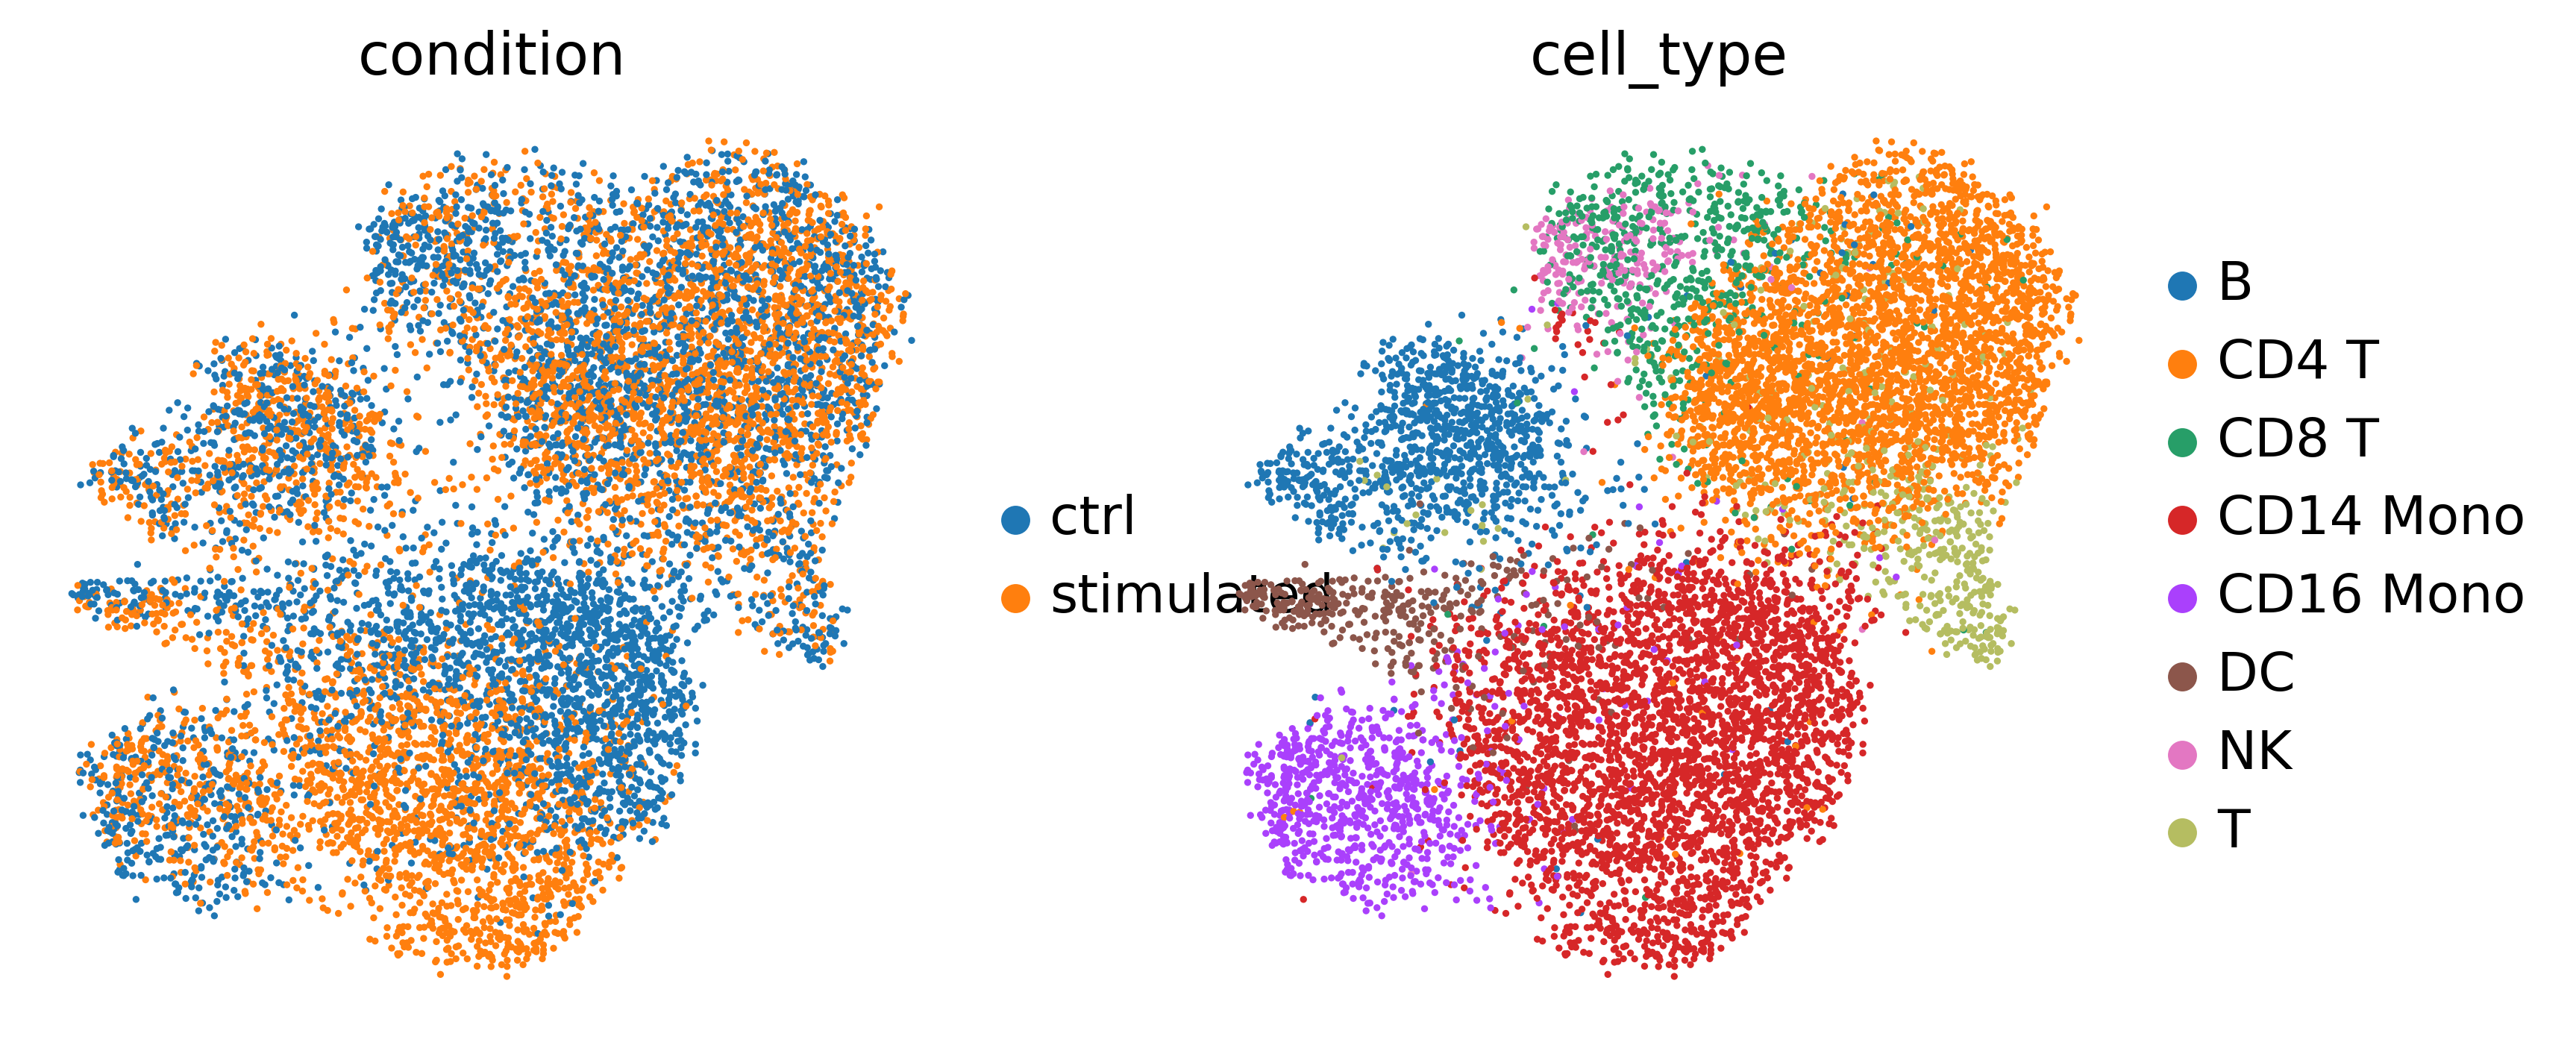

In [22]:
sc.pp.neighbors(latent_with_true_labels)
sc.tl.umap(latent_with_true_labels)
sc.pl.umap(latent_with_true_labels, color=[condition_key, cell_type_key],
           show=True,
           wspace=0.15,
           frameon=False)

         Falling back to preprocessing with `sc.pp.pca` and default params.


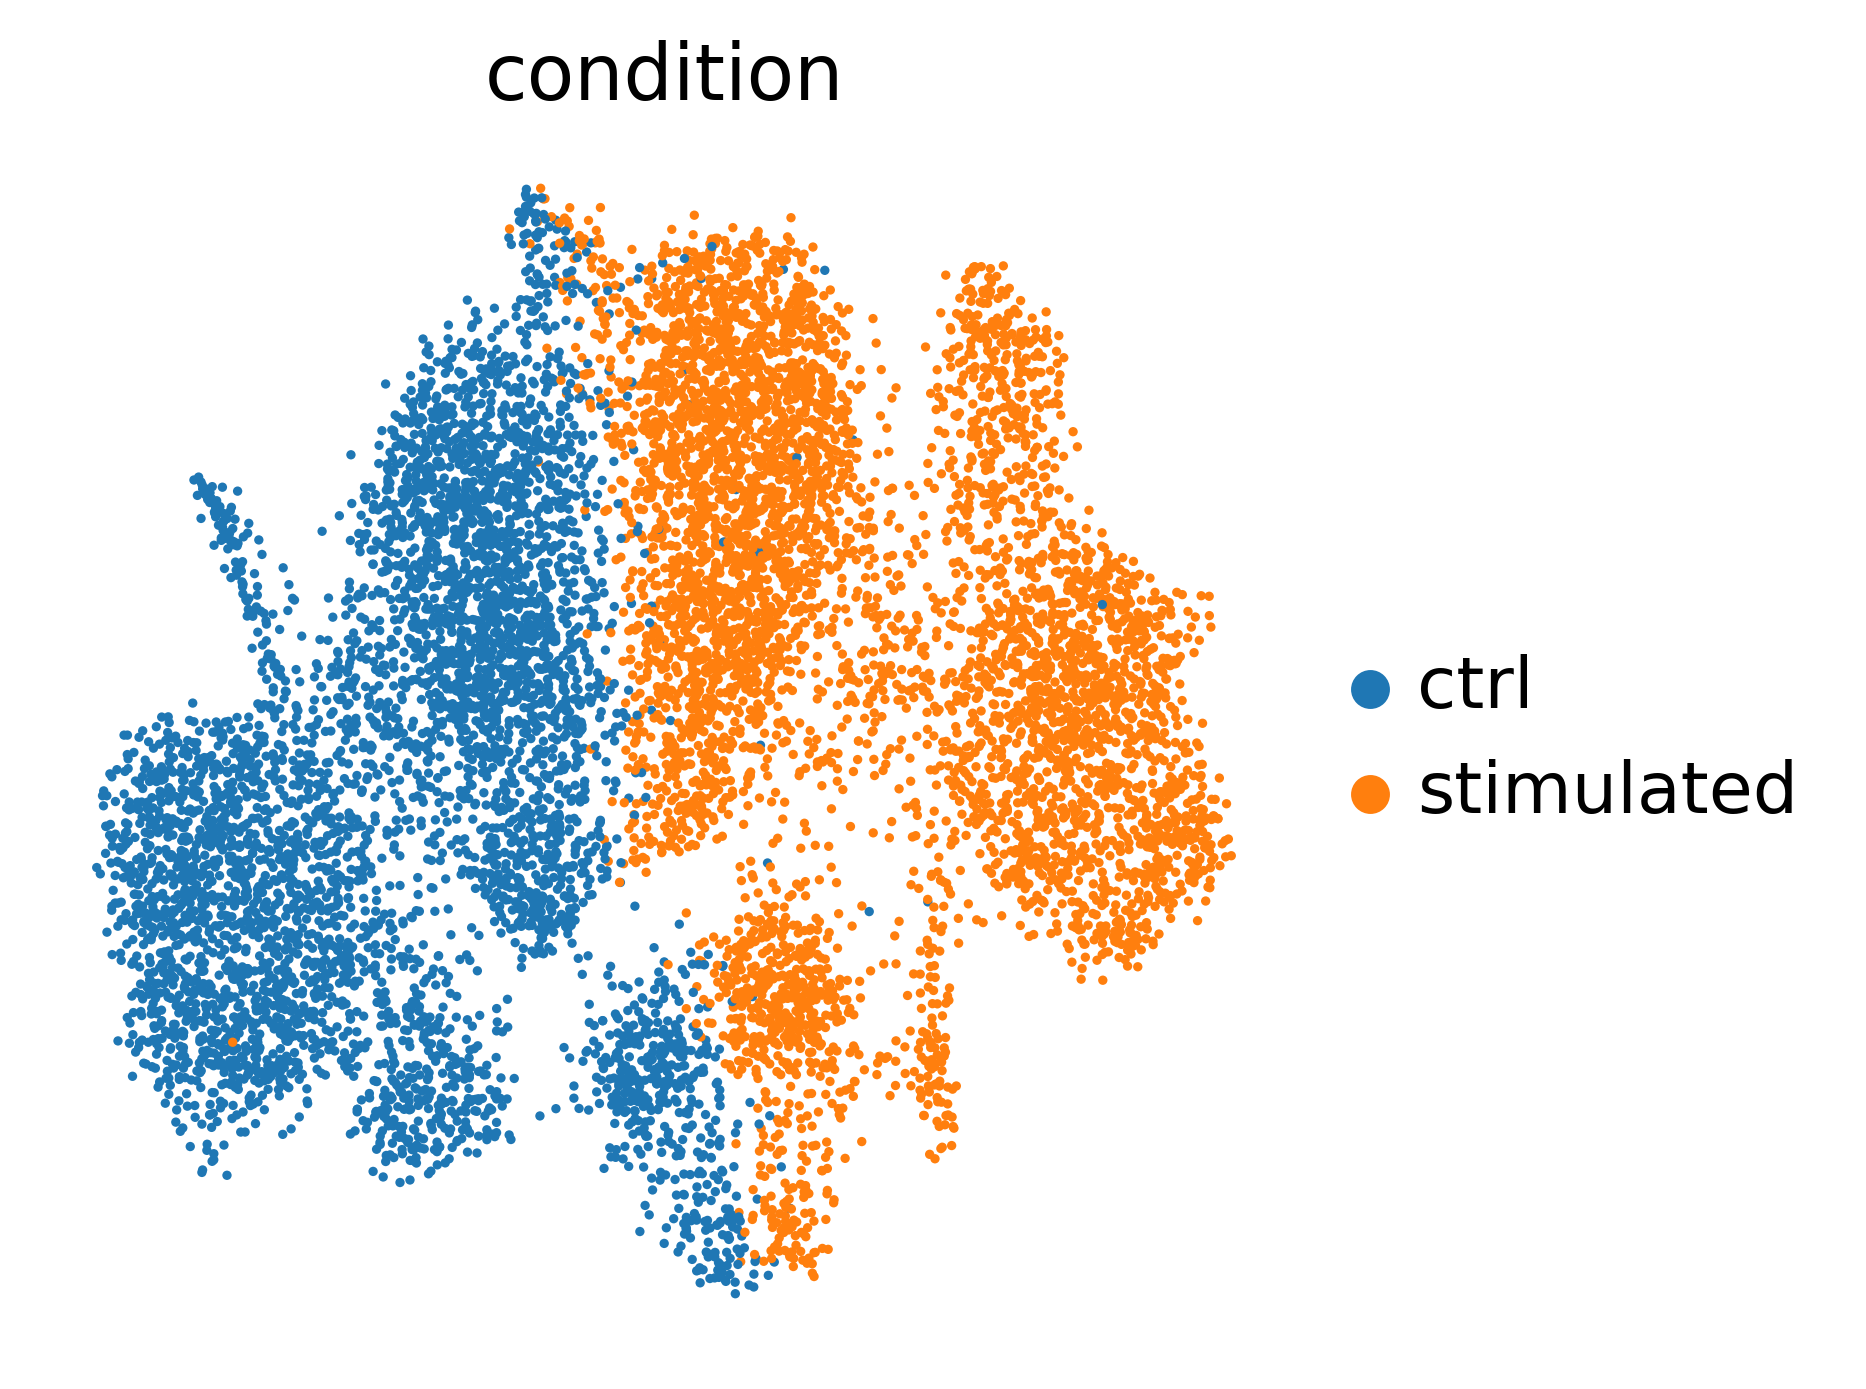

In [23]:
sc.pp.neighbors(mmd_with_true_labels)
sc.tl.umap(mmd_with_true_labels)
sc.pl.umap(mmd_with_true_labels, color=condition_key,
           show=True,
           save="_trVAE_MMD_condition.png",
           wspace=0.15,
           frameon=False)

In [24]:
cell_type_adata = train_adata[train_adata.obs[cell_type_key] == specific_celltype]

In [25]:
cell_type_adata.var = pd.DataFrame(index=cell_type_adata.var_names)

In [26]:
cell_type_adata.obs.groupby([cell_type_key, condition_key]).size()

cell_type  condition 
NK         ctrl          245
           stimulated    249
dtype: int64

In [27]:
def predict_transition(adata, source_cond, target_cond):
    
    source_adata = adata[adata.obs[condition_key] == source_cond]
    
    source_cond_key = source_cond.split("_to_")[-1]
    source_labels = np.zeros(source_adata.shape[0]) + label_encoder[source_cond_key]
    target_labels = np.zeros(source_adata.shape[0]) + label_encoder[target_cond]

    pred_target = network.predict(source_adata,
                                  encoder_labels=source_labels,
                                  decoder_labels=target_labels,
                                  )

    pred_adata = sc.AnnData(X=pred_target)
    pred_adata.obs[condition_key] = [source_cond + "_to_" + target_cond] * pred_target.shape[0]
    pred_adata.obs[cell_type_key] = [specific_celltype] * pred_target.shape[0]
    pred_adata.var_names = source_adata.var_names

    adata = adata.concatenate(pred_adata)
    return adata

In [28]:
# recon_adata = predict_transition(cell_type_adata, "CTRL", "STIM")
recon_adata = predict_transition(cell_type_adata, "ctrl", "stimulated")
recon_adata

/home/karimpour/miniconda3/envs/trvae_tensor/lib/python3.7/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],


AnnData object with n_obs × n_vars = 739 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'stim', 'seurat_annotations', 'integrated_snn_res.0.5', 'seurat_clusters', 'condition', 'cell_type', 'cov_cond', 'split_CD14 Mono', 'split_CD4 T', 'split_T', 'split_CD8 T', 'split_B', 'split_DC', 'split_CD16 Mono', 'split_NK', 'batch'

In [29]:
recon_adata.obs.groupby([cell_type_key, condition_key]).size()

cell_type  condition         
NK         ctrl                  245
           ctrl_to_stimulated    245
           stimulated            249
dtype: int64

In [30]:
# path = "CTRL_to_STIM"
path = "ctrl_to_stimulated"
from_condition = path.split("_to_")[-2]
to_condition = path.split("_to_")[-1]

In [31]:
pred_adata = recon_adata[recon_adata.obs[condition_key] == path]
pred_adata

View of AnnData object with n_obs × n_vars = 245 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'stim', 'seurat_annotations', 'integrated_snn_res.0.5', 'seurat_clusters', 'condition', 'cell_type', 'cov_cond', 'split_CD14 Mono', 'split_CD4 T', 'split_T', 'split_CD8 T', 'split_B', 'split_DC', 'split_CD16 Mono', 'split_NK', 'batch'

In [32]:
ctrl_adata = cell_type_adata[cell_type_adata.obs[condition_key] == from_condition]
ctrl_adata

View of AnnData object with n_obs × n_vars = 245 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'stim', 'seurat_annotations', 'integrated_snn_res.0.5', 'seurat_clusters', 'condition', 'cell_type', 'cov_cond', 'split_CD14 Mono', 'split_CD4 T', 'split_T', 'split_CD8 T', 'split_B', 'split_DC', 'split_CD16 Mono', 'split_NK'
    uns: 'hvg', 'log1p', 'rank_genes_groups_cov'
    layers: 'counts'

In [33]:
real_adata = cell_type_adata[cell_type_adata.obs[condition_key] == to_condition]
real_adata = reptrvae.utils.remove_sparsity(real_adata)
real_adata

View of AnnData object with n_obs × n_vars = 249 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'stim', 'seurat_annotations', 'integrated_snn_res.0.5', 'seurat_clusters', 'condition', 'cell_type', 'cov_cond', 'split_CD14 Mono', 'split_CD4 T', 'split_T', 'split_CD8 T', 'split_B', 'split_DC', 'split_CD16 Mono', 'split_NK'
    uns: 'hvg', 'log1p', 'rank_genes_groups_cov'
    layers: 'counts'

In [34]:
real_adata.X.min(), real_adata.X.max()

(ArrayView(0., dtype=float32), ArrayView(7.97627, dtype=float32))

In [35]:
pred_adata.X.min(), pred_adata.X.max()

(ArrayView(0., dtype=float32), ArrayView(7.4469447, dtype=float32))

In [36]:
pred_adata = reptrvae.utils.remove_sparsity(pred_adata)

In [37]:
pred_mean = np.mean(pred_adata.X, axis=0)
real_mean = np.mean(real_adata.X, axis=0)

In [38]:
pred_var = np.var(pred_adata.X, axis=0)
real_var = np.var(real_adata.X, axis=0)

In [41]:
m, b, r_value_mean, p_value, std_err = stats.linregress(pred_mean, real_mean)
r_value_mean = r_value_mean ** 2
r_value_mean

0.9202791109611164

In [42]:
from scipy.stats import pearsonr
corr = pearsonr(pred_mean, real_mean)[0]
corr

0.9593117902752545

In [43]:
m, b, r_value_var, p_value, std_err = stats.linregress(pred_var, real_var)
r_value_var = r_value_var ** 2
r_value_var

0.5958556738200095

In [44]:
adata_pred = ctrl_adata.concatenate(pred_adata, real_adata)
adata_pred

/home/karimpour/miniconda3/envs/trvae_tensor/lib/python3.7/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],


AnnData object with n_obs × n_vars = 739 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'stim', 'seurat_annotations', 'integrated_snn_res.0.5', 'seurat_clusters', 'condition', 'cell_type', 'cov_cond', 'split_CD14 Mono', 'split_CD4 T', 'split_T', 'split_CD8 T', 'split_B', 'split_DC', 'split_CD16 Mono', 'split_NK', 'batch'

In [45]:
adata_pred.obs[condition_key].unique()

array(['ctrl', 'ctrl_to_stimulated', 'stimulated'], dtype=object)

In [46]:
sc.tl.rank_genes_groups(cell_type_adata,
                        groupby=condition_key,
                        groups=[to_condition],
                        reference=from_condition,
                        n_genes=100)

In [47]:
top_genes = cell_type_adata.uns['rank_genes_groups']['names'][to_condition]

reg_mean_top100: 0.9278797172504393
reg_mean_all: 0.9202791109611164


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


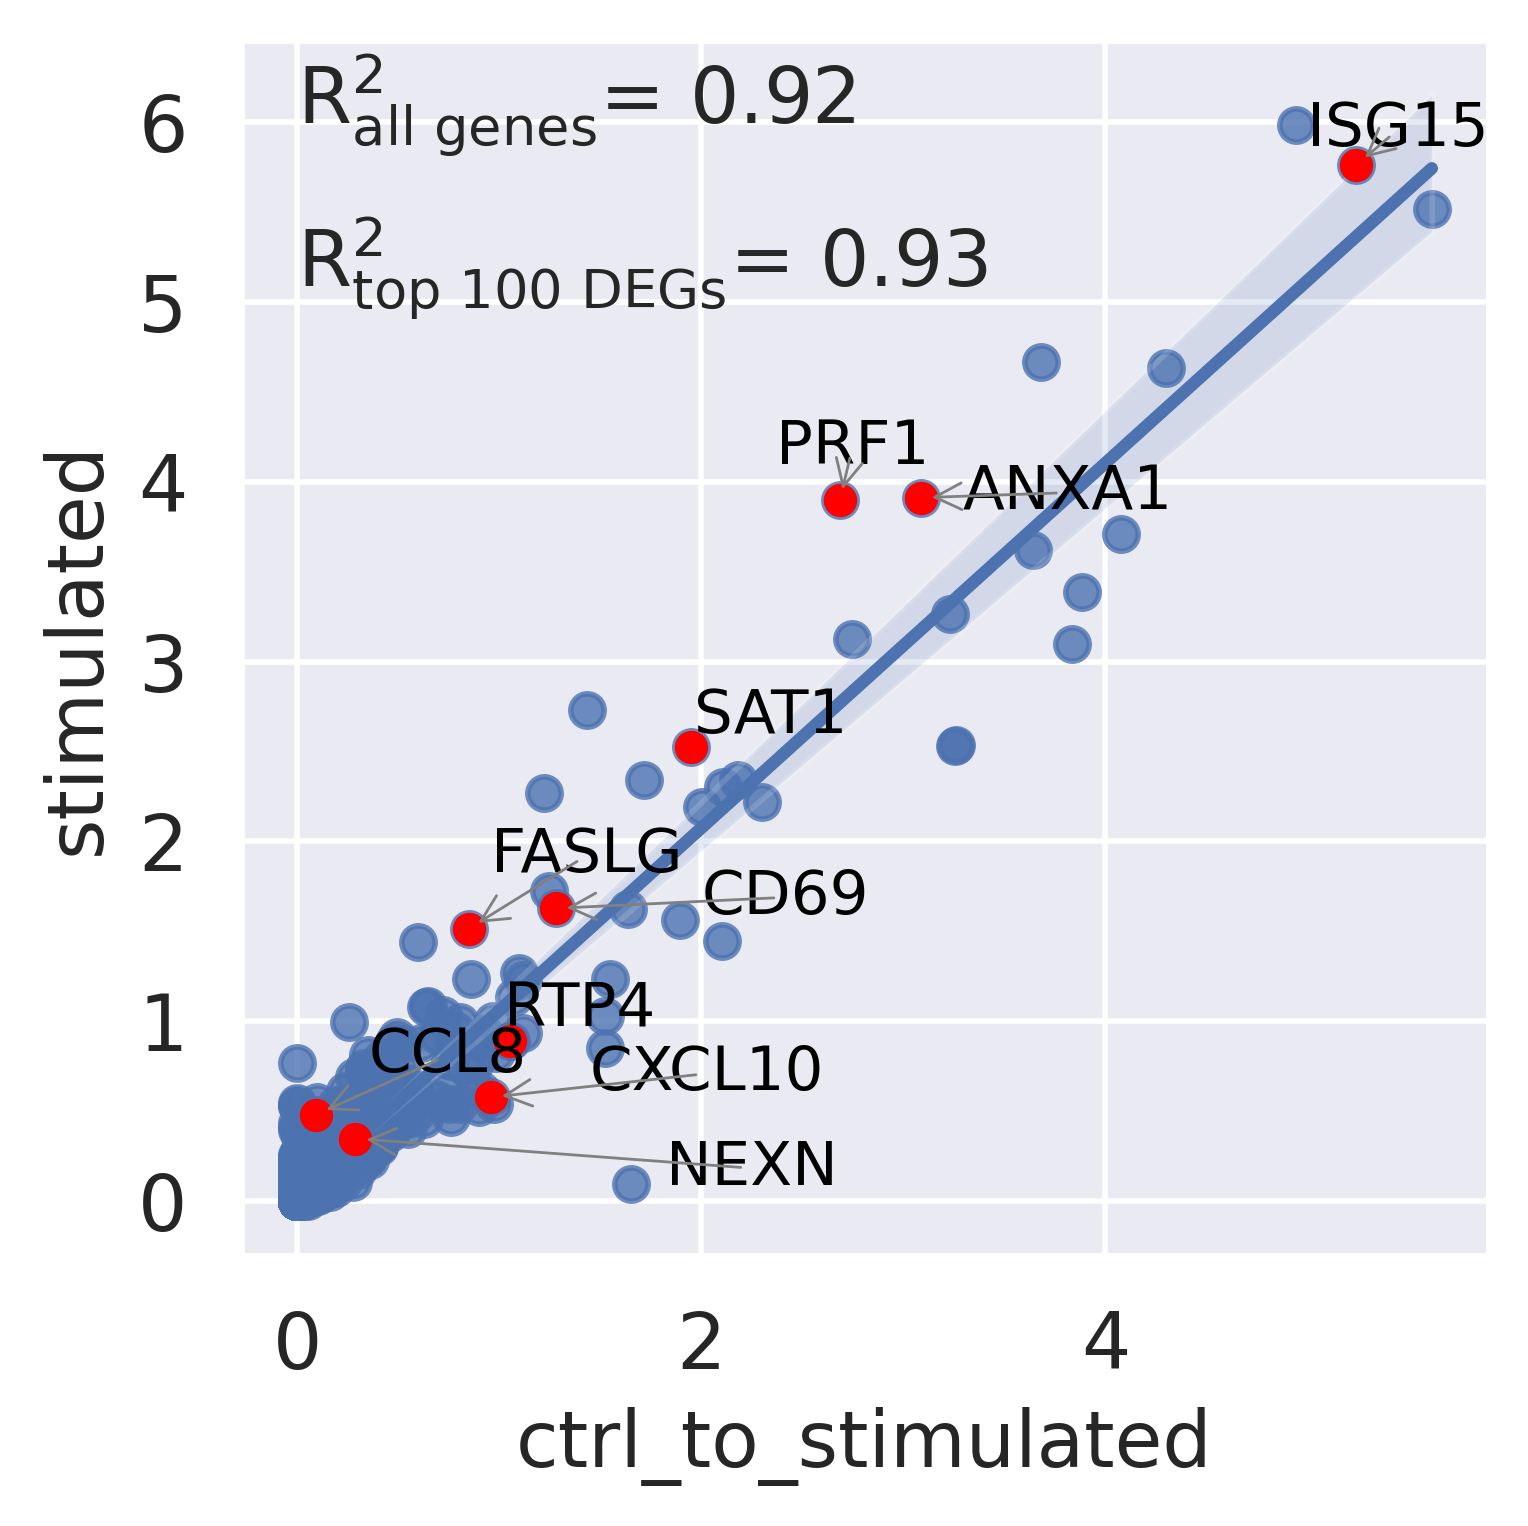

In [48]:
reptrvae.pl.reg_mean_plot(adata_pred,
                         top_100_genes=top_genes,
                         gene_list=top_genes[:10],
                         condition_key=condition_key,
                         axis_keys={'x': path, 'y': to_condition},
                         labels={'x': path, 'y': to_condition},
                         path_to_save=None,
                         legend=False,
                         show=True,
                         x_coeff=1.0,
                         y_coeff=0.0)

reg_var_top100: 0.5493390047434994
reg_var_all: 0.5958556738200095


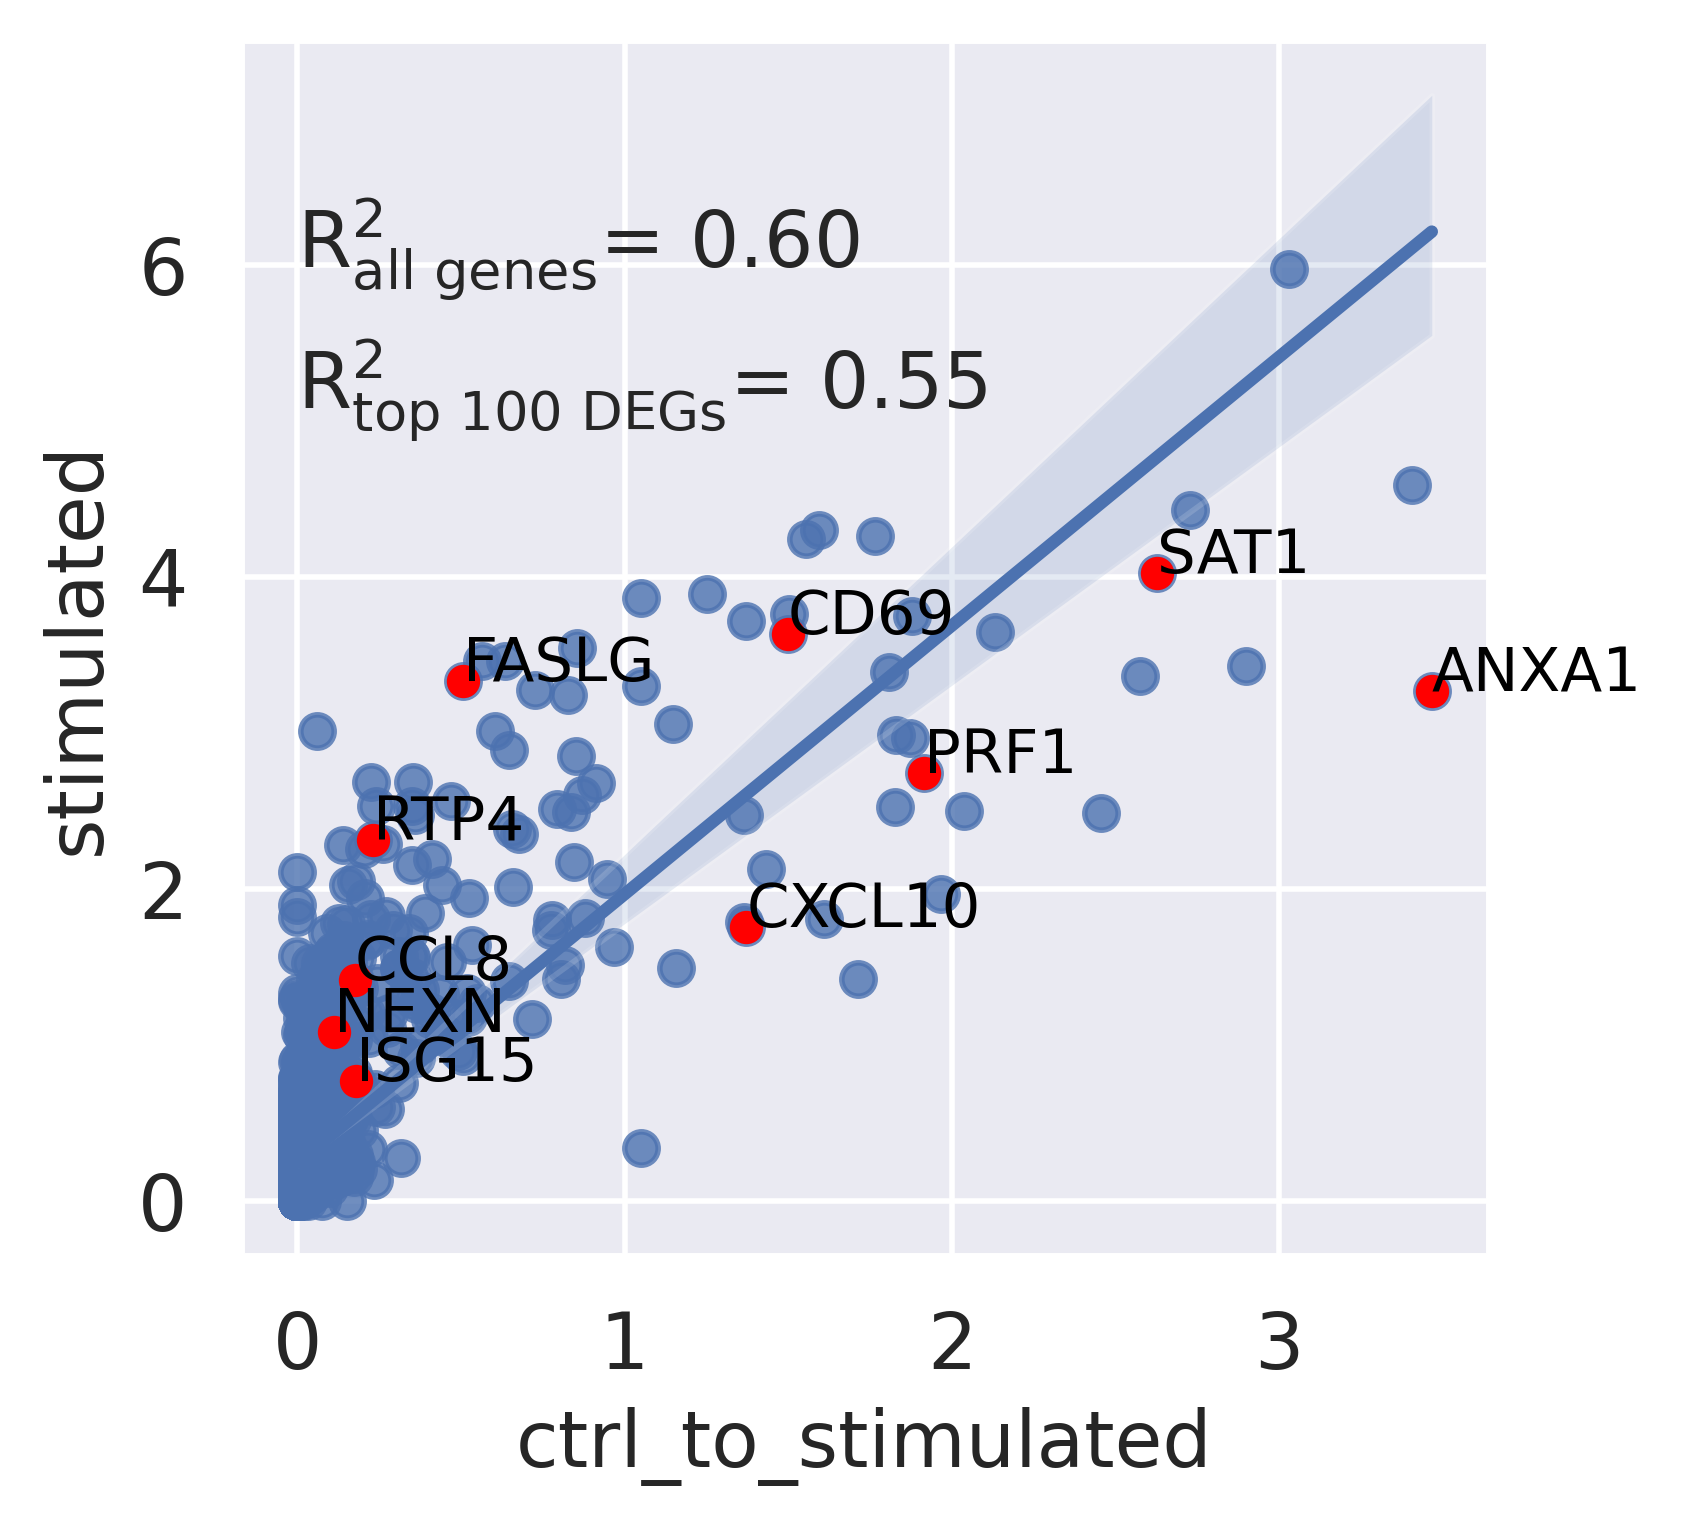

In [49]:
reptrvae.pl.reg_var_plot(adata_pred,
                     top_100_genes=top_genes,
                     gene_list=top_genes[:10],
                     condition_key=condition_key,
                     axis_keys={'x': path, 'y': to_condition},
                     labels={'x': path, 'y': to_condition},
                     path_to_save=None,
                     legend=False,
                     show=True,
                     x_coeff=1.0,
                     y_coeff=0.0)

In [50]:
top_genes

array(['ISG15', 'PRF1', 'SAT1', 'ANXA1', 'CXCL10', 'CCL8', 'RTP4',
       'FASLG', 'CD69', 'NEXN', 'ODF2L', 'SELL', 'RARRES3', 'TARBP1',
       'PMAIP1', 'RAD9A', 'GZMB', 'SOCS1', 'APOBEC3A', 'GZMA', 'CHST12',
       'SYNE2', 'LAMP3', 'SEC11C', 'CCL7', 'NUCB2', 'FAM26F', 'SBK1',
       'CCL3', 'HSPA1A', 'ANKRD49', 'PERP', 'APOBEC3B', 'RGS1', 'FAM65B',
       'DDHD1', 'ANXA2R', 'ZNF430', 'IL2RB', 'IGFBP7', 'IL1RN', 'LAG3',
       'MORC3', 'PIM1', 'PTPN4', 'CTD-2521M24.9', 'CDK2AP2', 'DDX20',
       'MTA1', 'PAXIP1-AS2', 'VAMP4', 'SMAGP', 'SPINK2', 'RFC1',
       'L3MBTL3', 'CCL2', 'UTRN', 'IFI27', 'FANCF', 'CHPF', 'CALCOCO2',
       'PLAC8', 'FUNDC1', 'IFNG', 'RARA', 'ADPRM', 'TBC1D14', 'RABEP2',
       'MARS2', 'RP11-51J9.5', 'BLMH', 'ACN9', 'GNLY', 'IL2RA', 'SOD2',
       'FUT7', 'PATL2', 'SS18', 'MIR155HG', 'SLA', 'TMEM9', 'ICOS',
       'LY75', 'PVRL3', 'SLC18B1', 'WWC3', 'ZWILCH', 'FAM135A', 'KIF19',
       'AC093391.2', 'GRPEL2', 'ZIK1', 'RP11-489E7.4', 'NUFIP2', 'PRKCI',
       '

In [51]:
adata_pred.obs[condition_key].value_counts()

stimulated            249
ctrl                  245
ctrl_to_stimulated    245
Name: condition, dtype: int64

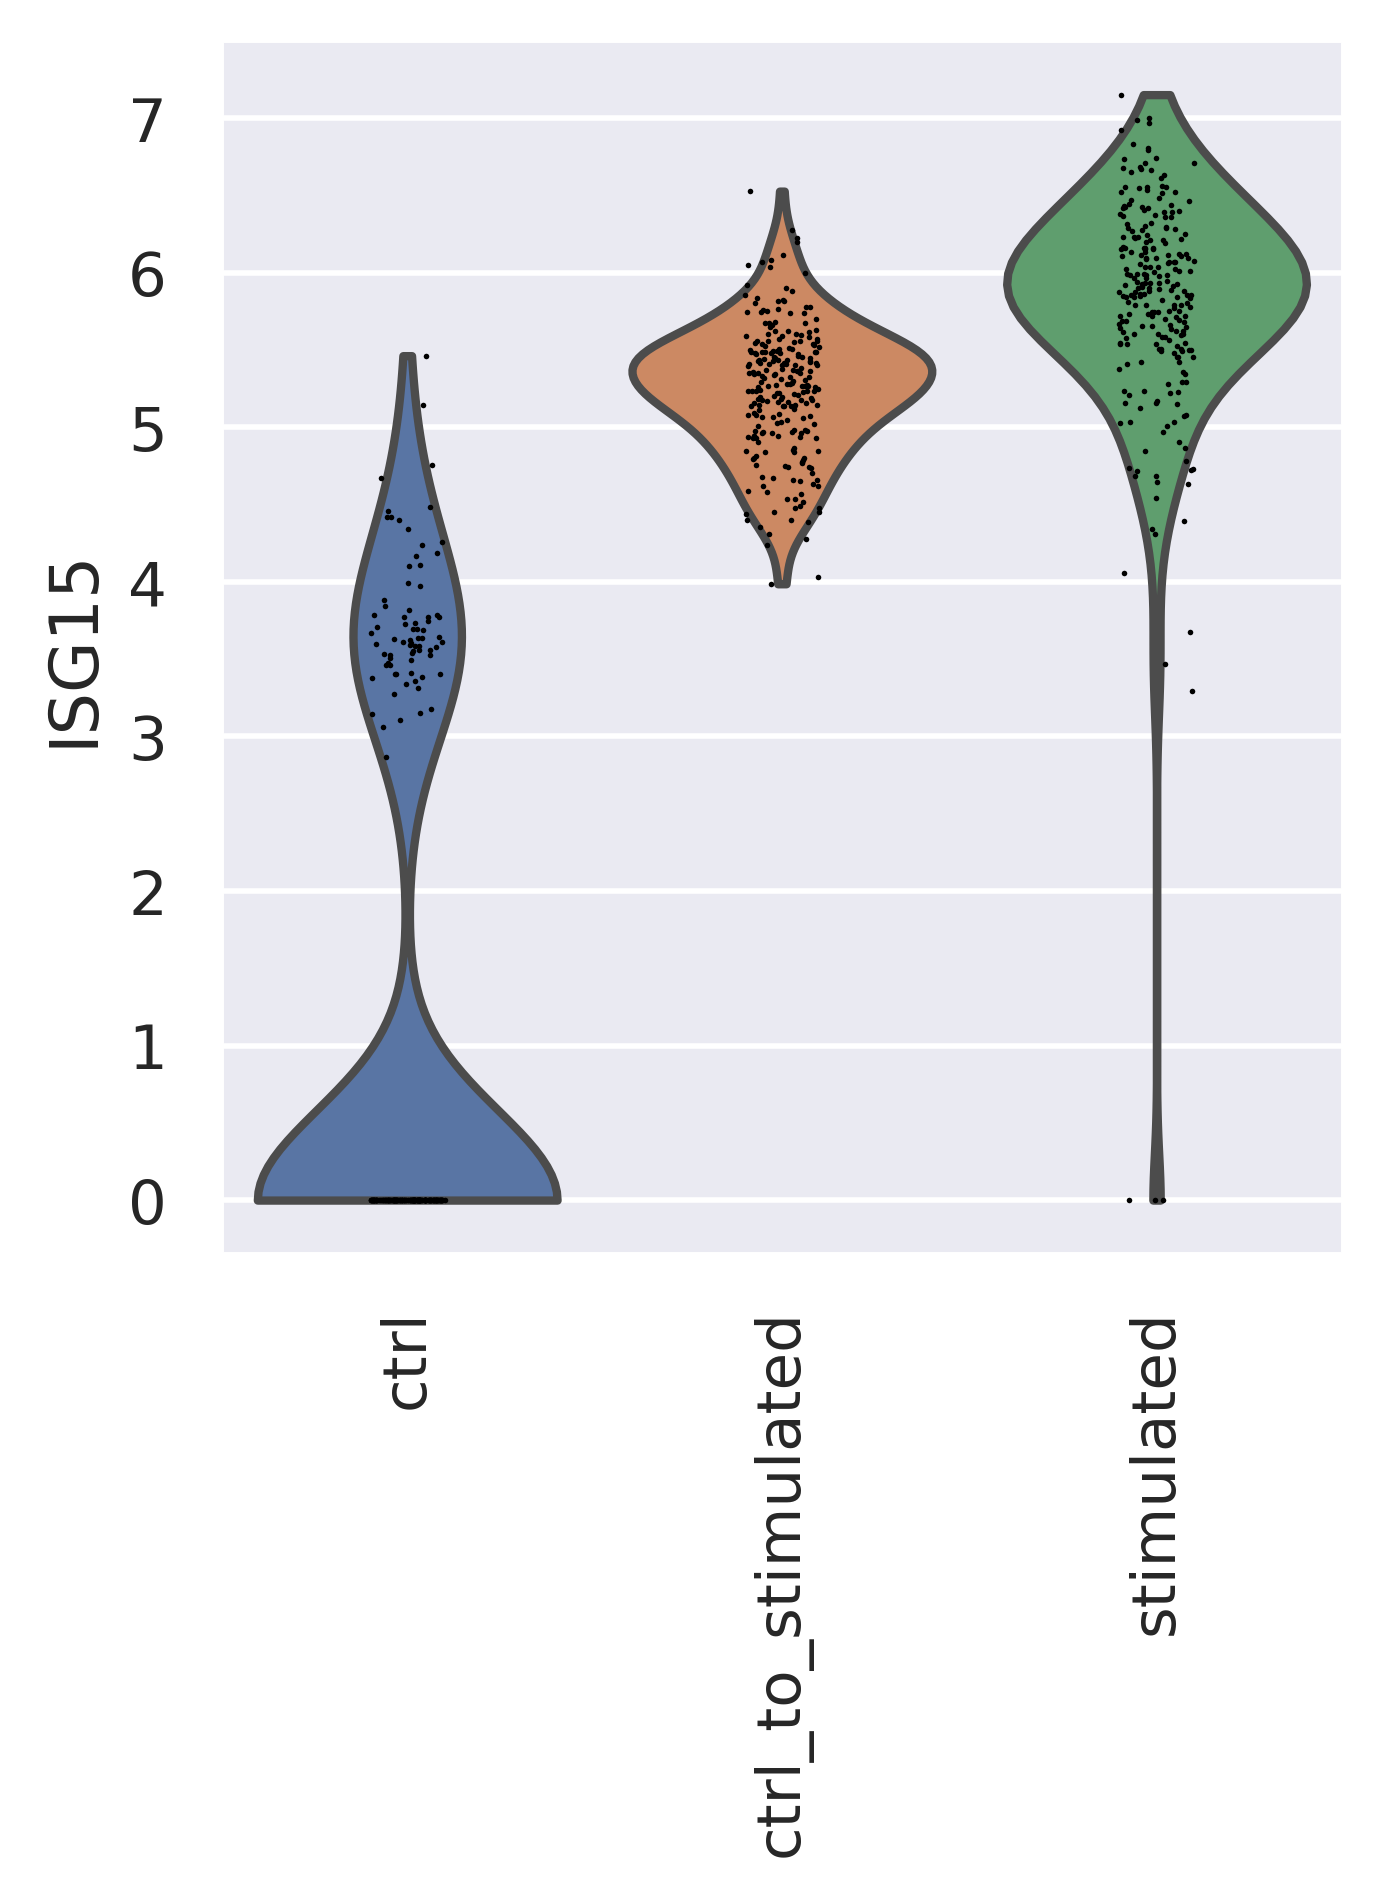

In [52]:
sc.pl.violin(adata_pred, groupby=condition_key, keys=top_genes[0], rotation=90)

In [58]:
recon_adata.write_h5ad(f"../trVAE_reproducibility/data/reconstructed/trVAE_{data_name}/{specific_celltype}.h5ad")

FileNotFoundError: [Errno 2] Unable to create file (unable to open file: name = '../trVAE_reproducibility/data/reconstructed/trVAE_kang/NK.h5ad', errno = 2, error message = 'No such file or directory', flags = 13, o_flags = 242)

In [59]:
network.model_to_use = f"./models/trVAEMulti/best/{data_name}-{specific_celltype}/"

In [60]:
network.model_to_use

'./models/trVAEMulti/best/kang-NK/'

In [61]:
network.save_model()